# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Nur Nabila Amalia]
- **Email:** [ds128b6x1409@student.devacademy.id]
- **ID Dicoding:** [nur_nabila_amalis139]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata jumlah penyewaan sepeda harian antara pengguna casual dan registered berdasarkan perubahan musim (season) selama periode tahun 2011 hingga 2012?
- **Pertanyaan 2:** Pada rentang jam berapa puncak penyewaan sepeda terjadi pada hari kerja (workingday) dibandingkan hari libur atau akhir pekan sepanjang tahun 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## Data Wrangling

In [6]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Gathering Data

#### Load Dataset Bike Sharing (Day & Hour)

In [7]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Dataset `day.csv` memuat 731 data penyewaan sepeda harian dan `hour.csv` memuat 17.379 data penyewaan per jam dari tahun 2011–2012.

### Assessing Data

#### Identifying Data Types and Missing Values

In [8]:
print("=== Info day_df ===")
day_df.info()
print("\nMissing value day_df:", day_df.isna().sum().sum())
print("Duplikat day_df:", day_df.duplicated().sum())

print("\n=== Info hour_df ===")
hour_df.info()
print("\nMissing value hour_df:", hour_df.isna().sum().sum())
print("Duplikat hour_df:", hour_df.duplicated().sum())

=== Info day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing value day_df: 0
Duplikat day_df: 0

=== Info hour_df ===
<class 

**Steps to Take:**
- Mengubah tipe data kolom `dteday` dari string/object menjadi `datetime`.
- Mengubah kode angka pada kolom `season`, `yr`, dan `weathersit` menjadi teks keterangan yang jelas.

**Insight:** (Opsional)
- Tidak ada missing value maupun data duplikat pada kedua dataset.
- Masalah yang ditemukan adalah tipe data tanggal (`dteday`) belum berbentuk `datetime` dan beberapa kolom kategori masih memakai angka.

### Cleaning Data

#### Fixing Data Types and Category Labels

In [9]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

season_labels = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
year_labels = {0: 2011, 1: 2012}
weather_labels = {
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Snow/Rain",
    4: "Heavy Rain/Ice"
}

for data in [day_df, hour_df]:
    data["season"] = data["season"].map(season_labels)
    data["yr"] = data["yr"].map(year_labels)
    data["weathersit"] = data["weathersit"].map(weather_labels)

day_df[["dteday", "season", "yr", "weathersit"]].head()

,dteday,season,yr,weathersit
0,2011-01-01,Spring,2011,Mist/Cloudy
1,2011-01-02,Spring,2011,Mist/Cloudy
2,2011-01-03,Spring,2011,Clear/Partly Cloudy
3,2011-01-04,Spring,2011,Clear/Partly Cloudy
4,2011-01-05,Spring,2011,Clear/Partly Cloudy


**Insight:** (Opsional)
- Kolom `dteday` sudah berubah menjadi format tanggal (`datetime`) dan label kategori (`season`, `yr`, `weathersit`) sudah tampil dalam bentuk teks yang mudah dibaca.

## Exploratory Data Analysis (EDA)

### Explore Penyewaan Sepeda Berdasarkan Musim dan Pola Jam

In [10]:
# Rangkuman rata-rata penyewaan per musim
season_agg = day_df.groupby("season")[["casual", "registered", "cnt"]].mean().round(1)
display(season_agg)

# Rangkuman rata-rata penyewaan per jam (Hari Kerja vs Libur)
hour_pivot = hour_df.pivot_table(index="hr", columns="workingday", values="cnt", aggfunc="mean").round(1)
hour_pivot.columns = ["Akhir Pekan / Libur", "Hari Kerja"]
display(hour_pivot)

,casual,registered,cnt
season,,,
Fall,1202.6,4441.7,5644.3
Spring,334.9,2269.2,2604.1
Summer,1106.1,3886.2,4992.3
Winter,729.1,3999.1,4728.2


,Akhir Pekan / Libur,Hari Kerja
hr,,
0,90.8,36.8
1,69.5,16.6
2,53.2,8.7
3,25.8,4.9
4,8.3,5.4
5,8.7,24.9
6,18.7,102.5
7,43.4,290.6
8,105.7,477.0


**Insight:** (Opsional)
- Musim gugur (*Fall*) memiliki rata-rata penyewaan harian tertinggi, sedangkan musim semi (*Spring*) terendah. Pengguna `registered` mendominasi di semua musim.
- Pada hari kerja, penyewaan tinggi di jam 08:00 dan 17:00–18:00. Pada hari libur/akhir pekan, penyewaan tinggi di jam 12:00–16:00.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

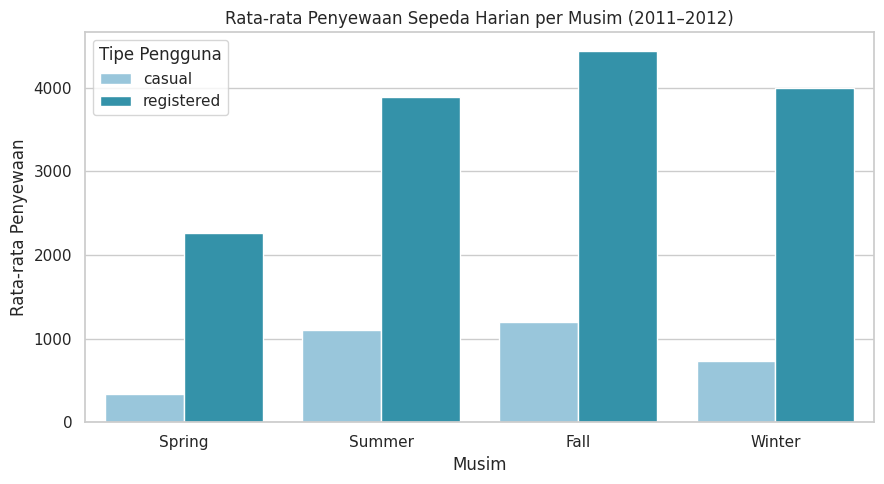

In [11]:
season_order = ["Spring", "Summer", "Fall", "Winter"]
season_plot = day_df.groupby("season")[["casual", "registered"]].mean().reindex(season_order).reset_index()
season_melted = season_plot.melt(id_vars="season", var_name="Tipe Pengguna", value_name="Rata-rata Penyewaan")

plt.figure(figsize=(9, 5))
sns.barplot(data=season_melted, x="season", y="Rata-rata Penyewaan", hue="Tipe Pengguna", palette=["#8ECAE6", "#219EBC"])
plt.title("Rata-rata Penyewaan Sepeda Harian per Musim (2011–2012)")
plt.xlabel("Musim")
plt.ylabel("Rata-rata Penyewaan")
plt.tight_layout()
plt.show()

### Pertanyaan 2:

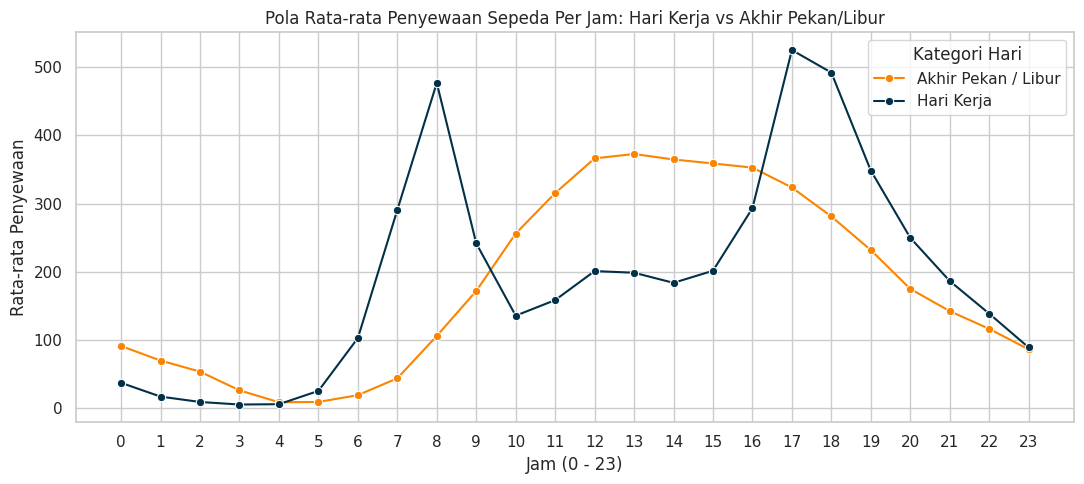

In [12]:
hourly_pattern = hour_df.groupby(["workingday", "hr"])["cnt"].mean().reset_index()

plt.figure(figsize=(11, 5))
ax = sns.lineplot(data=hourly_pattern, x="hr", y="cnt", hue="workingday", marker="o", palette=["#FB8500", "#023047"])
plt.title("Pola Rata-rata Penyewaan Sepeda Per Jam: Hari Kerja vs Akhir Pekan/Libur")
plt.xlabel("Jam (0 - 23)")
plt.ylabel("Rata-rata Penyewaan")
plt.xticks(range(0, 24))
handles, _ = ax.get_legend_handles_labels()
plt.legend(handles, ["Akhir Pekan / Libur", "Hari Kerja"], title="Kategori Hari")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik pertama memperlihatkan bahwa penyewaan tertinggi terjadi di musim gugur (*Fall*) dan musim panas (*Summer*), didominasi oleh pengguna terdaftar (*registered*).
- Grafik kedua memperlihatkan dua pola berbeda: hari kerja memiliki dua puncak di jam berangkat (08:00) dan pulang kerja (17:00), sedangkan akhir pekan memiliki satu puncak landai di siang hingga sore hari (12:00–16:00).

## Analisis Lanjutan (Opsional)

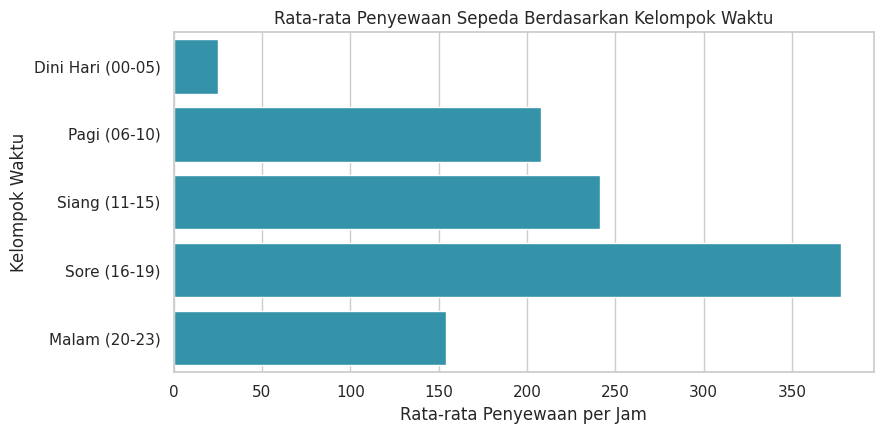

In [13]:
bins = [-1, 5, 10, 15, 19, 24]
labels = ["Dini Hari (00-05)", "Pagi (06-10)", "Siang (11-15)", "Sore (16-19)", "Malam (20-23)"]

hour_df["kelompok_waktu"] = pd.cut(hour_df["hr"], bins=bins, labels=labels)
waktu_summary = hour_df.groupby("kelompok_waktu", observed=False)["cnt"].mean().reset_index()

plt.figure(figsize=(9, 4.5))
sns.barplot(data=waktu_summary, x="cnt", y="kelompok_waktu", color="#219EBC")
plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Kelompok Waktu")
plt.xlabel("Rata-rata Penyewaan per Jam")
plt.ylabel("Kelompok Waktu")
plt.tight_layout()
plt.show()

# Simpan data bersih untuk dashboard Streamlit
hour_df.to_csv("dashboard/main_data.csv", index=False)

**Insight:** (Opsional)
- Kelompok waktu **Sore (16-19)** memiliki rata-rata penyewaan tertinggi, sedangkan **Dini Hari (00-05)** paling sepi.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Penyewaan sepeda mencapai puncaknya pada musim gugur (*Fall*) dan terendah pada musim semi (*Spring*), dengan pengguna *registered* sebagai penyumbang mayoritas penyewaan di seluruh musim.
- **Conclusion pertanyaan 2:** Puncak penyewaan pada hari kerja terjadi pada pukul 08:00 dan 17:00–18:00 (jam komuter), sedangkan pada akhir pekan/libur memuncak pada pukul 12:00–16:00 (jam rekreasi).

**Rekomendasi Action Item:**
- Menambah stok sepeda di area perkantoran/stasiun menjelang pukul 08:00 dan 17:00 pada hari kerja, serta memfokuskan stok di area wisata/taman pada pukul 12:00–16:00 saat akhir pekan.
- Melakukan perawatan rutin armada sepeda pada rentang waktu Dini Hari (00:00–05:00) atau musim semi (*Spring*) saat permintaan paling rendah.